# Estética com matplotlib

Neste notebook partimos do gráfico padrão do matplotlib e melhoramos a figura passo a passo, aplicando os conceitos da aula: rótulos com unidades, sobreposição de pontos, escala logarítmica, ordem das categorias e uso de cor.

Os dados são de cerca de 54 mil diamantes, com peso em quilates (`carat`), qualidade do corte (`cut`), cor, pureza e preço em dólares.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Fonte um pouco maior em todos os gráficos
plt.rcParams["font.size"] = 12

In [3]:
df = pd.read_csv("../dados/diamonds.csv")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## 1. O gráfico padrão

Preço em função do peso, sem nenhum ajuste.

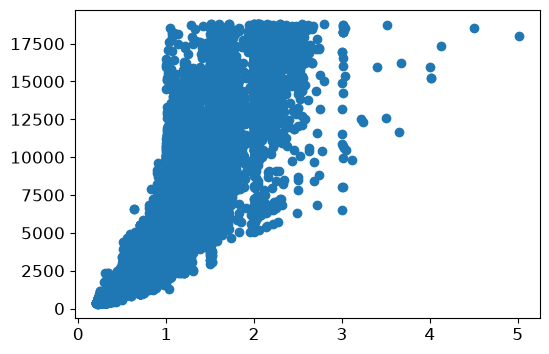

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"])

Problemas: os eixos não dizem o que está sendo mostrado, os pontos se sobrepõem e formam uma mancha, e a maior parte dos diamantes está espremida no canto inferior esquerdo.

## 2. Rótulos com unidades

Todo eixo precisa dizer qual variável representa e em qual unidade.

Text(0, 0.5, 'Preço (US$)')

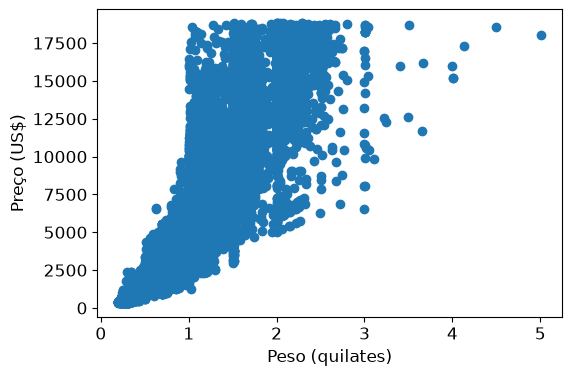

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"])
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")

## 3. Pontos sobrepostos

Com milhares de pontos, diminuímos o tamanho (`s`) e usamos transparência (`alpha`). Regiões com muitos diamantes ficam mais escuras.

Text(0, 0.5, 'Preço (US$)')

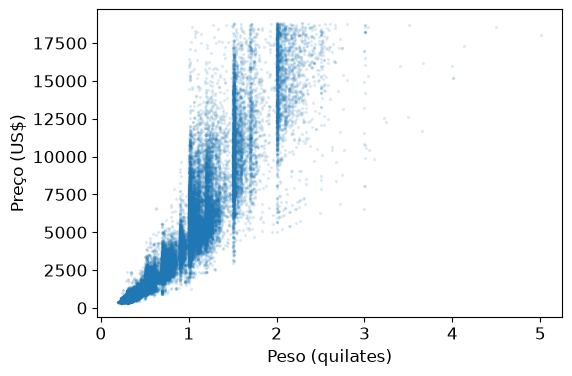

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"], s=2, alpha=0.1)
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")

## 4. Escala logarítmica

Peso e preço variam em mais de uma ordem de grandeza. Na escala log, os diamantes pequenos deixam de ficar espremidos e a relação entre peso e preço fica próxima de uma reta. Os rótulos continuam mostrando os valores originais.

Text(0, 0.5, 'Preço (US$)')

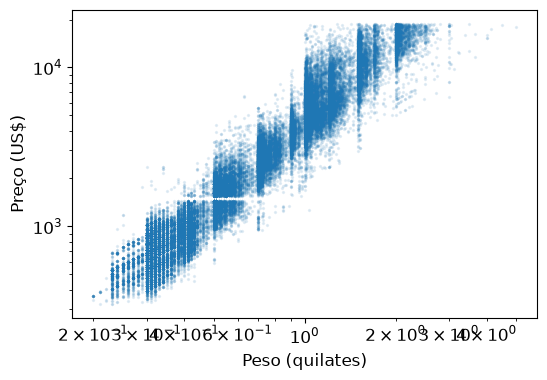

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"], s=2, alpha=0.1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")

Os rótulos padrão da escala log ficam sobrepostos no eixo x e aparecem como potências de 10 no eixo y. Escolhemos marcas em valores redondos e desligamos as marcas menores. Como vamos repetir isso nos próximos gráficos, colocamos o código em uma função.

In [ ]:
def set_log_ticks(ax):
    """Cria marcas em valores redondos, escritas como números comuns."""
    x_ticks = [0.25, 0.5, 1, 2, 4]
    y_ticks = [500, 1000, 2000, 5000, 10000]
    ax.set_xticks(x_ticks, labels=x_ticks)
    ax.set_yticks(y_ticks, labels=y_ticks)
    ax.minorticks_off()

Text(0, 0.5, 'Preço (US$)')

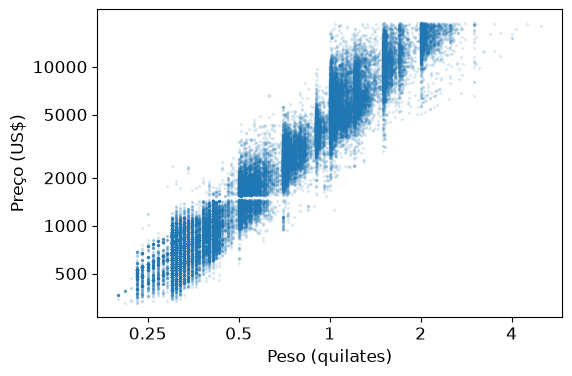

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"], s=2, alpha=0.1)
ax.set_xscale("log")
ax.set_yscale("log")
set_log_ticks(ax)
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")

## 5. Removendo elementos desnecessários

As bordas de cima e da direita não trazem informação. Uma grade clara ajuda a ler os valores sem competir com os dados. Esses ajustes também vão para uma função, que usaremos em todos os gráficos.

In [19]:
def make_pretty(ax, use_grid=True):
    """Torna o gráfico mais bonito."""

    # Remove as bordas de cima e da direita
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    # Bordas restantes em cinza escuro no lugar do preto
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")

    if use_grid:
        # Grade clara, desenhada atrás dos dados
        ax.grid(color="#e0e0e0")
        ax.set_axisbelow(True)

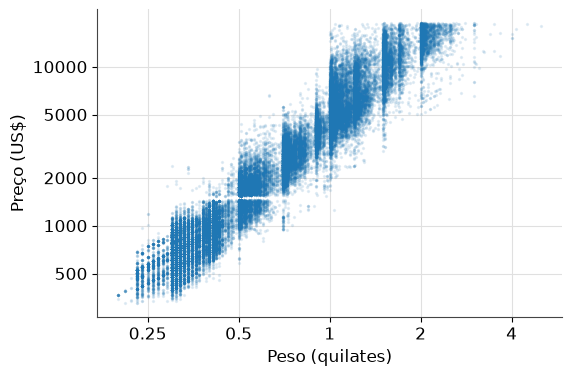

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"], s=2, alpha=0.1)
ax.set_xscale("log")
ax.set_yscale("log")
set_log_ticks(ax)
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")
make_pretty(ax)

## 6. Cor para destacar

Para chamar a atenção para uma categoria, desenhamos todos os diamantes em cinza e, por cima, só os da categoria escolhida em uma cor forte. Aqui destacamos os diamantes com pureza `I1`, a pior da escala. O título pode dizer qual é a mensagem do gráfico.

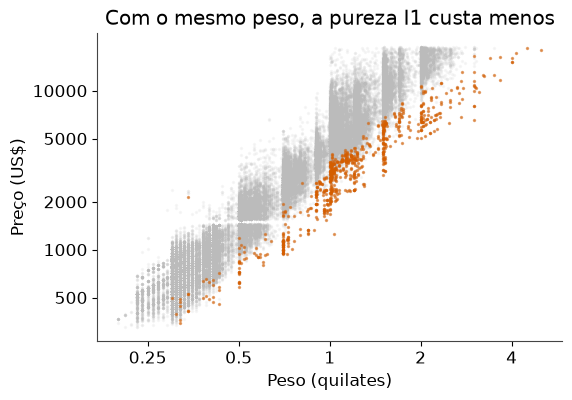

In [21]:
# Diamantes da categoria que queremos destacar
highlight = df[df["clarity"] == "I1"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["carat"], df["price"], s=2, alpha=0.1, color="#bbbbbb")
ax.scatter(highlight["carat"], highlight["price"], s=2, alpha=0.5, color="#d55e00")
ax.set_xscale("log")
ax.set_yscale("log")
set_log_ticks(ax)
ax.set_xlabel("Peso (quilates)")
ax.set_ylabel("Preço (US$)")
ax.set_title("Com o mesmo peso, a pureza I1 custa menos")
# Removemos o grid porque ele se mistura com os pontos cinzas
make_pretty(ax, use_grid=False)

## 7. Salvando a figura

`dpi` controla a resolução e `bbox_inches="tight"` corta as margens em branco. Para documentos impressos, formatos vetoriais como `.pdf` e `.svg` costumam ser melhores.

In [13]:
# Salvando a figura no formato rasterizado (png)
fig.savefig("diamantes.png", dpi=200, bbox_inches="tight")

# Salvando a figura no formato vetorial (pdf)
fig.savefig("diamantes.pdf", bbox_inches="tight")